# CS 5326 PA3: Search over Reasoning and Step-Level Process Reward Models
Generator: `Qwen2.5-1.5B-Instruct` (fp16, cuda:0) · Judge: `Qwen2.5-7B-Instruct` (4-bit NF4, cuda:1) · Benchmark: 50 GSM8K problems

## Setup

In [1]:
import os

if not os.path.exists("cs5326-pa3-starter"):
    !git clone -q https://github.com/ahmad-sarfraz345/cs5326-pa3-starter.git
%cd cs5326-pa3-starter


!pip install -q -U bitsandbytes

/kaggle/working/cs5326-pa3-starter


## Problem 1: Step-Structured Generation & Baseline Decoders
Step/answer parsing, step prompt, greedy decoding, and self-consistency with majority voting.

In [2]:
%%writefile src/extraction.py
"""
src/extraction.py - Step and answer extraction utilities.
"""
import re

# "Step 3:" style label, allowing markdown like "**Step 3:**" or "### Step 3."
_STEP_LABEL = r"[#*`\s]*Step\s*\d+\s*[:.]?[#*`\s]*"
_STEP_PATTERN = (
    r"(?:^|\n)\s*(?:" + _STEP_LABEL + r")(.*?)"
    r"(?=(?:\n\s*" + _STEP_LABEL + r")|(?:\n\s*[#*`\s]*Final Answer)|$)"
)

# Everything after the LAST "Final Answer" label on its line
_FINAL_LINE = re.compile(r"final\s*answer\s*[*:#`\s]*([^\n]*)", re.IGNORECASE)

# A number at the start of that text, e.g. "$1,234", "-5", "18.00", "\boxed{18}"
_NUMBER = re.compile(r"^[\s$`*(]*(?:\\boxed\{)?[\s$]*(-?\d[\d,]*(?:\.\d+)?)")


def parse_steps(completion_text: str) -> list[str]:
    """Returns the text of each 'Step k:' block, with markdown decoration removed."""
    if not completion_text or not isinstance(completion_text, str):
        return []
    matches = re.findall(_STEP_PATTERN, completion_text, flags=re.DOTALL | re.IGNORECASE)
    cleaned = []
    for m in matches:
        text = m.strip().strip("*#`").strip()
        if text:
            cleaned.append(text)
    return cleaned


def extract_answer(completion_text: str) -> int | None:
    """Returns the integer after the last 'Final Answer', or None. Never raises."""
    try:
        if not completion_text or not isinstance(completion_text, str):
            return None

        lines = _FINAL_LINE.findall(completion_text)
        if not lines:
            return None
        last = lines[-1].strip()

        match = _NUMBER.match(last)
        if not match:
            return None

        value = float(match.group(1).replace(",", ""))
        if not value.is_integer():
            return None  # e.g. 18.5 is not a valid integer answer
        return int(value)
    except Exception:
        return None

Overwriting src/extraction.py


In [3]:
%%writefile src/generation.py
"""
src/generation.py - Prompt formatting and baseline generation routines.
"""
import time
from typing import Any, Callable

from .extraction import extract_answer, parse_steps

GenerateFn = Callable[[str, int, dict], list[dict]]

GREEDY_KWARGS = {
    "do_sample": False, "temperature": None, "top_p": None, "top_k": None,
    "max_new_tokens": 512,
}


def sampling_kwargs(temperature: float = 0.7) -> dict:
    """Pure temperature sampling (overrides Qwen's default top_p/top_k/repetition_penalty)."""
    return {
        "do_sample": True, "temperature": temperature, "top_p": 1.0, "top_k": 0,
        "repetition_penalty": 1.0, "max_new_tokens": 512,
    }


def _get_generate_fn(model: Any, tokenizer: Any, generate_fn: GenerateFn | None) -> GenerateFn:
    """Use the given generate_fn, or build a Hugging Face one from model + tokenizer."""
    if generate_fn is not None:
        return generate_fn
    from .utils import make_hf_generate_fn
    return make_hf_generate_fn(model, tokenizer)


def format_step_prompt(question: str) -> str:
    """Zero-shot prompt that forces numbered steps and a 'Final Answer: <int>' line."""
    return (
        "Solve the following math word problem step by step.\n\n"
        "Rules:\n"
        "- Write each step on its own line, starting with \"Step 1:\", \"Step 2:\", and so on.\n"
        "- Each step should do one small deduction or calculation and show the arithmetic.\n"
        "- Use plain text only. Do not use markdown, headings, bold, LaTeX, or \\boxed{}.\n"
        "- After the last step, write one final line in exactly this form: Final Answer: <integer>\n"
        "- The final line must contain only the number (no units, no $ sign, no words).\n\n"
        f"Problem: {question}\n\n"
        "Use this format:\n"
        "Step 1: ...\n"
        "Step 2: ...\n"
        "Final Answer: <integer>"
    )


def compute_majority_vote(answers: list[int | None]) -> int | None:
    """Most common non-None answer; ties go to the answer that appeared first."""
    counts: dict[int, int] = {}
    first_seen: list[int] = []
    for a in answers:
        if a is None:
            continue
        if a not in counts:
            counts[a] = 0
            first_seen.append(a)
        counts[a] += 1

    if not counts:
        return None
    best_count = max(counts.values())
    for a in first_seen:  # earliest answer with the top count wins
        if counts[a] == best_count:
            return a
    return None


def _make_candidate(output: dict) -> dict:
    text = output["text"]
    return {
        "completion": text,
        "steps": parse_steps(text),
        "answer": extract_answer(text),
        "num_tokens": int(output["num_tokens"]),
    }


def run_greedy(
    model: Any = None,
    tokenizer: Any = None,
    question: str = "",
    generate_fn: GenerateFn | None = None,
) -> dict[str, Any]:
    """One deterministic completion (N = 1)."""
    gen = _get_generate_fn(model, tokenizer, generate_fn)
    prompt = format_step_prompt(question)

    start = time.perf_counter()
    output = gen(prompt, 1, dict(GREEDY_KWARGS))[0]
    elapsed = time.perf_counter() - start

    cand = _make_candidate(output)
    return {
        "prompt": prompt,
        "completion": cand["completion"],
        "steps": cand["steps"],
        "answer": cand["answer"],
        "generation_calls": 1,
        "generated_tokens": cand["num_tokens"],
        "time_seconds": elapsed,
    }


def sample_candidates(gen: GenerateFn, question: str, n: int, temperature: float) -> list[dict]:
    """Draw n sampled completions and turn them into candidate dicts."""
    if n <= 0:
        return []
    outputs = gen(format_step_prompt(question), n, sampling_kwargs(temperature))
    return [_make_candidate(o) for o in outputs]


def run_self_consistency(
    model: Any = None,
    tokenizer: Any = None,
    question: str = "",
    n: int = 5,
    temperature: float = 0.7,
    generate_fn: GenerateFn | None = None,
) -> dict[str, Any]:
    """Sample n paths and majority-vote over their answers."""
    gen = _get_generate_fn(model, tokenizer, generate_fn)

    start = time.perf_counter()
    candidates = sample_candidates(gen, question, n, temperature)
    elapsed = time.perf_counter() - start

    return {
        "candidates": candidates,
        "answer": compute_majority_vote([c["answer"] for c in candidates]),
        "generation_calls": len(candidates),
        "generated_tokens": sum(c["num_tokens"] for c in candidates),
        "time_seconds": elapsed,
    }

Overwriting src/generation.py


## Problem 2: Process Reward Model (PRM) Verifier
Step-level judge prompt (local validity), verdict parser, and per-step path scoring.

In [4]:
%%writefile src/prm_judge.py
"""
src/prm_judge.py - PRM judge prompt construction, parsing, and step scoring.
"""
import re
from typing import Any, Callable

JudgeFn = Callable[[str], dict]

_VERDICT_LINE = re.compile(r"verdict\s*:\s*\**\s*(VALID|INVALID)\b", re.IGNORECASE)
_NEGATIVE = re.compile(r"\bINVALID\b|\bNOT\s+VALID\b", re.IGNORECASE)
_POSITIVE = re.compile(r"\bVALID\b", re.IGNORECASE)
_RATIONALE = re.compile(r"rationale\s*:\s*([^\n]*)", re.IGNORECASE)
# First sentence: stop at . ! ? only when followed by whitespace or end (so "2.5" is kept)
_FIRST_SENTENCE = re.compile(r"^(.*?[.!?])(?=\s|$)")


def build_prm_judge_prompt(question: str, preceding_steps: list[str], current_step: str) -> str:
    """Prompt asking the judge whether ONE step is locally valid."""
    if preceding_steps:
        previous = "\n".join(f"Step {i}: {s}" for i, s in enumerate(preceding_steps, start=1))
    else:
        previous = "(no preceding steps)"

    return (
        "You are a careful math teacher checking ONE step of a student's solution.\n\n"
        f"Problem:\n{question}\n\n"
        f"Preceding steps:\n{previous}\n\n"
        f"Current Step: {current_step}\n\n"
        "Instructions:\n"
        "- Assume all preceding steps are correct, even if they look wrong.\n"
        "- Judge ONLY the Current Step.\n"
        "- The Current Step is VALID if its arithmetic is correct and it follows logically "
        "from the problem and the preceding steps.\n"
        "- The Current Step is INVALID if it has a calculation mistake, uses a wrong number "
        "or quantity from the problem, or makes an unjustified deduction.\n"
        "- Recompute every calculation in the Current Step yourself before deciding.\n\n"
        "Answer with exactly two lines:\n"
        "Verdict: VALID   (or)   Verdict: INVALID\n"
        "Rationale: <one short sentence>"
    )


def parse_judge_decision(judge_output: str) -> tuple[float, str]:
    """Turn judge text into (+1.0 or -1.0, one-sentence rationale)."""
    if not judge_output or not isinstance(judge_output, str):
        return -1.0, ""

    # 1) explicit "Verdict: ..." line (first one wins)
    m = _VERDICT_LINE.search(judge_output)
    if m:
        score = 1.0 if m.group(1).upper() == "VALID" else -1.0
    # 2) negative words checked BEFORE "VALID" (because "INVALID" contains "VALID")
    elif _NEGATIVE.search(judge_output):
        score = -1.0
    # 3) standalone VALID
    elif _POSITIVE.search(judge_output):
        score = 1.0
    # 4) unparseable -> INVALID
    else:
        score = -1.0

    rationale = ""
    r = _RATIONALE.search(judge_output)
    if r:
        line = r.group(1)
        s = _FIRST_SENTENCE.match(line)
        rationale = (s.group(1) if s else line).strip()

    return score, rationale


def score_path(
    judge_model: Any = None,
    judge_tokenizer: Any = None,
    question: str = "",
    candidate: dict[str, Any] | None = None,
    judge_fn: JudgeFn | None = None,
) -> dict[str, Any]:
    """Judge every step of a candidate. Step t sees steps[:t] as context."""
    if judge_fn is None:
        from .utils import make_hf_judge_fn
        judge_fn = make_hf_judge_fn(judge_model, judge_tokenizer)

    steps = list((candidate or {}).get("steps") or [])
    step_scores, rationales, judge_texts = [], [], []
    judge_tokens = 0

    for t, step in enumerate(steps):
        prompt = build_prm_judge_prompt(question, steps[:t], step)
        out = judge_fn(prompt)
        score, rationale = parse_judge_decision(out.get("text", ""))
        step_scores.append(score)
        rationales.append(rationale)
        judge_texts.append(out.get("text", ""))
        judge_tokens += int(out.get("num_tokens", 0))

    return {
        "step_scores": step_scores,
        "rationales": rationales,
        "judge_texts": judge_texts,
        "judge_calls": len(steps),
        "judge_tokens": judge_tokens,
    }

Overwriting src/prm_judge.py


## Problem 3: PRM-Guided Best-of-N Search & Budget Bookkeeping
Path aggregation (min / product / step penalty), filter-then-vote selection, Best-of-N, and compute-matched self-consistency.

In [5]:
%%writefile src/search.py
"""
src/search.py - Path aggregation, Best-of-N search, and compute-matched search.
"""
import time
from typing import Any, Callable

from .generation import _get_generate_fn, compute_majority_vote, sample_candidates
from .prm_judge import score_path

GenerateFn = Callable[[str, int, dict], list[dict]]
JudgeFn = Callable[[str], dict]

TIE_TOL = 1e-9


def aggregate_path_score(
    step_scores: list[float],
    strategy: str = "min",
    penalty_lambda: float = 2.0,
) -> float:
    """Reduce step scores (+1 / -1) to one path score."""
    if strategy not in ("min", "product", "step_penalty"):
        raise ValueError(f"Unknown aggregation strategy: {strategy}")
    if not step_scores:
        return -1.0

    if strategy == "min":
        return float(min(step_scores))

    if strategy == "product":
        prob = 1.0
        for r in step_scores:
            p = min(max((r + 1.0) / 2.0, 0.01), 0.99)  # clamp to [0.01, 0.99]
            prob *= p
        return prob

    # step_penalty
    mean = sum(step_scores) / len(step_scores)
    num_invalid = sum(1 for r in step_scores if r == -1.0)
    return float(mean - penalty_lambda * num_invalid)


def select_best_path(
    candidate_paths: list[dict[str, Any]],
    aggregation_strategy: str = "min",
    penalty_lambda: float = 2.0,
) -> dict[str, Any]:
    """Filter -> score -> take best -> break ties by majority vote."""
    if not candidate_paths:
        raise ValueError("candidate_paths is empty")

    scores = [
        aggregate_path_score(c.get("step_scores") or [], aggregation_strategy, penalty_lambda)
        for c in candidate_paths
    ]

    # 1) eligibility: drop answer=None if any candidate has a real answer
    indices = list(range(len(candidate_paths)))
    if any(c.get("answer") is not None for c in candidate_paths):
        indices = [i for i in indices if candidate_paths[i].get("answer") is not None]

    # 2) tied set = everyone within tolerance of the best score
    best = max(scores[i] for i in indices)
    tied = [i for i in indices if abs(scores[i] - best) <= TIE_TOL]

    # 3) tie-break with majority vote over the tied answers
    chosen = tied[0]
    if len(tied) > 1:
        vote = compute_majority_vote([candidate_paths[i].get("answer") for i in tied])
        if vote is not None:
            chosen = next(i for i in tied if candidate_paths[i].get("answer") == vote)

    result = dict(candidate_paths[chosen])  # shallow copy, input untouched
    result["path_score"] = float(scores[chosen])
    result["num_tied"] = len(tied)
    return result


def run_prm_best_of_n(
    model: Any = None,
    judge_model: Any = None,
    gen_tokenizer: Any = None,
    judge_tokenizer: Any = None,
    question: str = "",
    n: int = 5,
    aggregation_strategy: str = "min",
    penalty_lambda: float = 2.0,
    candidates: list[dict[str, Any]] | None = None,
    generate_fn: GenerateFn | None = None,
    judge_fn: JudgeFn | None = None,
) -> dict[str, Any]:
    """Sample (or reuse) n paths, judge every step, pick the best path."""
    start = time.perf_counter()

    generation_calls, generated_tokens = 0, 0
    if candidates is None:
        gen = _get_generate_fn(model, gen_tokenizer, generate_fn)
        candidates = sample_candidates(gen, question, n, temperature=0.7)
        generation_calls = len(candidates)
        generated_tokens = sum(c["num_tokens"] for c in candidates)

    if judge_fn is None:
        from .utils import make_hf_judge_fn
        judge_fn = make_hf_judge_fn(judge_model, judge_tokenizer)

    scored, judge_calls, judge_tokens = [], 0, 0
    for c in candidates:
        res = score_path(question=question, candidate=c, judge_fn=judge_fn)
        new_c = dict(c)
        new_c["step_scores"] = res["step_scores"]
        new_c["rationales"] = res["rationales"]
        new_c["judge_texts"] = res["judge_texts"]
        scored.append(new_c)
        judge_calls += res["judge_calls"]
        judge_tokens += res["judge_tokens"]

    selected = select_best_path(scored, aggregation_strategy, penalty_lambda)

    return {
        "selected": selected,
        "answer": selected.get("answer"),
        "candidates": scored,
        "generation_calls": generation_calls,
        "judge_calls": judge_calls,
        "generated_tokens": generated_tokens,
        "judge_tokens": judge_tokens,
        "time_seconds": time.perf_counter() - start,
    }


def run_compute_matched_self_consistency(
    model: Any = None,
    tokenizer: Any = None,
    question: str = "",
    target_calls: int = 15,
    temperature: float = 0.7,
    existing_candidates: list[dict[str, Any]] | None = None,
    generate_fn: GenerateFn | None = None,
) -> dict[str, Any]:
    """Self-consistency with target_calls samples, reusing existing ones."""
    existing = list(existing_candidates or [])
    deficit = max(0, target_calls - len(existing))

    start = time.perf_counter()
    new = []
    if deficit > 0:
        gen = _get_generate_fn(model, tokenizer, generate_fn)
        new = sample_candidates(gen, question, deficit, temperature)
    elapsed = time.perf_counter() - start

    all_cands = existing + new
    return {
        "candidates": all_cands,
        "answer": compute_majority_vote([c.get("answer") for c in all_cands]),
        "generation_calls": len(new),
        "total_samples": len(all_cands),
        "generated_tokens": sum(c["num_tokens"] for c in new),
        "time_seconds": elapsed,
    }

Overwriting src/search.py


In [6]:
!python tests/test_public_adapter_smoke.py

Running 20 public adapter smoke tests...
  [PASS] test_format_step_prompt
  [PASS] test_parse_steps_plain
  [PASS] test_parse_steps_markdown_decorated
  [PASS] test_extract_answer_required_behaviors
  [PASS] test_extract_answer_resilience
  [PASS] test_compute_majority_vote
  [PASS] test_run_greedy
  [PASS] test_run_self_consistency
  [PASS] test_build_prm_judge_prompt_structure
  [PASS] test_parse_judge_decision
  [PASS] test_score_path
  [PASS] test_aggregate_path_score
  [PASS] test_select_best_path_clear_winner
  [PASS] test_select_best_path_tie_broken_by_majority
  [PASS] test_select_best_path_answer_none_exclusion
  [PASS] test_select_best_path_all_answers_none
  [PASS] test_run_prm_best_of_n_standalone
  [PASS] test_run_prm_best_of_n_with_shared_candidates
  [PASS] test_run_compute_matched_self_consistency
  [PASS] test_scaling_curve_consistency
Test Summary: 20 passed, 0 failed.
ALL TESTS PASSED SUCCESSFULLY!


## Problem 4: Evaluation, Comparative Analysis & Report

In [7]:
import json, time, random
import numpy as np
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import submission_adapter as A
from src.utils import set_seed_for_problem, load_models, make_hf_generate_fn, make_hf_judge_fn

OUT_DIR = "outputs"
GREEDY_CACHE = f"{OUT_DIR}/greedy_cache.jsonl"
PER_PROBLEM = f"{OUT_DIR}/per_problem.jsonl"
os.makedirs(OUT_DIR, exist_ok=True)

N_SHARED, N_MATCHED, TEMPERATURE = 5, 15, 0.7
STRATEGIES = ["min", "product", "step_penalty"]

def load_jsonl(path):
    if not os.path.exists(path):
        return []
    with open(path) as f:
        return [json.loads(line) for line in f if line.strip()]

def append_jsonl(path, record):
    with open(path, "a") as f:
        f.write(json.dumps(record) + "\n")

problems = load_jsonl("data/gsm8k_test_50.jsonl")

gen_model, gen_tokenizer, judge_model, judge_tokenizer = load_models(
    generator_device="cuda:0", judge_device="cuda:1")
gen_fn = make_hf_generate_fn(gen_model, gen_tokenizer)
judge_fn = make_hf_judge_fn(judge_model, judge_tokenizer)

print(len(problems), "problems")
for i in range(torch.cuda.device_count()):
    print(f"cuda:{i}", torch.cuda.get_device_name(i),
          f"{torch.cuda.memory_allocated(i) / 1e9:.2f} GB")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


... (11 outputs left out)

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

50 problems
cuda:0 Tesla T4 3.09 GB
cuda:1 Tesla T4 5.56 GB


In [8]:
# Greedy baseline (N=1) on all 50 problems, cached so a rerun resumes
greedy_done = {r["id"]: r for r in load_jsonl(GREEDY_CACHE)}

for idx, p in enumerate(tqdm(problems, desc="Greedy")):
    if p["id"] in greedy_done:
        continue
    set_seed_for_problem(idx)
    res = A.run_greedy(question=p["question"], generate_fn=gen_fn)
    rec = {"id": p["id"], **{k: res[k] for k in
           ["completion", "steps", "answer", "generated_tokens", "time_seconds"]}}
    append_jsonl(GREEDY_CACHE, rec)
    greedy_done[p["id"]] = rec

compliant = sum(greedy_done[p["id"]]["answer"] is not None for p in problems)
correct = sum(greedy_done[p["id"]]["answer"] == p["ground_truth_answer"] for p in problems)
print(f"Format compliance: {compliant}/50 | Greedy accuracy: {100 * correct / 50:.1f}%")
print("\nExample output:\n" + greedy_done[problems[0]["id"]]["completion"])

Greedy:   0%|          | 0/50 [00:00<?, ?it/s]

Format compliance: 44/50 | Greedy accuracy: 58.0%

Example output:
Step 1: Calculate the total number of eggs laid per day.
Janet's ducks lay 16 eggs per day.

Step 2: Determine how many eggs Janet eats for breakfast.
Janet eats 3 eggs for breakfast every morning.

Step 3: Subtract the eggs eaten for breakfast from the total to find out how many eggs are left after breakfast.
Total eggs - Eggs eaten for breakfast = Remaining eggs

Remaining eggs = 16 - 3 = 13 eggs

Step 4: Subtract the eggs used to bake muffins from the remaining eggs to find out how many eggs are left for selling.
Remaining eggs - Eggs used to bake muffins = Eggs for sale

Eggs for sale = 13 - 4 = 9 eggs

Step 5: Calculate the amount of money Janet makes from selling the eggs.
Price per egg = $2

Money made = Number of eggs sold × Price per egg

Money made = 9 × 2 = $18

Final Answer: 18


In [9]:
# Shared pool: 5 candidates (SC@5 + all PRM variants), +10 for SC@15.
# The 5 shared candidates are judged once; step scores are reused by every strategy.
done = {r["id"] for r in load_jsonl(PER_PROBLEM)}

for idx, p in enumerate(tqdm(problems, desc="Sampling + judging")):
    if p["id"] in done:
        continue
    set_seed_for_problem(idx)
    q, gt = p["question"], p["ground_truth_answer"]

    sc5 = A.run_self_consistency(question=q, n=N_SHARED, temperature=TEMPERATURE,
                                 generate_fn=gen_fn)
    sc15 = A.run_compute_matched_self_consistency(
        question=q, target_calls=N_MATCHED, temperature=TEMPERATURE,
        existing_candidates=sc5["candidates"], generate_fn=gen_fn)
    prm = A.run_prm_best_of_n(question=q, n=N_SHARED, aggregation_strategy="min",
                              candidates=sc5["candidates"], judge_fn=judge_fn)
    scored = prm["candidates"]

    preds, tied, sel_time = {}, {}, {}
    for s in STRATEGIES:
        t0 = time.perf_counter()
        sel = A.select_best_path(scored, aggregation_strategy=s, penalty_lambda=2.0)
        sel_time[s] = time.perf_counter() - t0
        preds[f"prm_{s}"], tied[s] = sel["answer"], sel["num_tied"]

    g = greedy_done[p["id"]]
    preds.update({"greedy": g["answer"], "sc5": sc5["answer"], "sc15": sc15["answer"]})

    append_jsonl(PER_PROBLEM, {
        "id": p["id"], "question": q, "ground_truth": gt,
        "greedy": g,
        "candidates": scored + sc15["candidates"][N_SHARED:],   # 15, in sampling order
        "judge_calls": prm["judge_calls"], "judge_tokens": prm["judge_tokens"],
        "times": {"greedy": g["time_seconds"], "sc5": sc5["time_seconds"],
                  "sc15_extra": sc15["time_seconds"], "judging": prm["time_seconds"],
                  **{f"select_{s}": sel_time[s] for s in STRATEGIES}}, 
        "predictions": preds, "num_tied": tied,
        "correct": {k: v == gt for k, v in preds.items()},
    })

Sampling + judging:   0%|          | 0/50 [00:00<?, ?it/s]

In [10]:
# Evaluation artifacts: results_summary.json, aggregation_ablation.json, sc_scaling_curve.json
records = load_jsonl(PER_PROBLEM)
assert len(records) == 50, f"{len(records)}/50 problems finished, rerun the cell above"
N = len(records)

acc = lambda key: round(100 * sum(r["correct"][key] for r in records) / N, 2)
avg_gen = lambda k: round(sum(sum(c["num_tokens"] for c in r["candidates"][:k]) for r in records) / N, 2)
t = lambda key: sum(r["times"][key] for r in records)
judge_calls = sum(r["judge_calls"] for r in records)
avg_judge_tok = round(sum(r["judge_tokens"] for r in records) / N, 2)
greedy_tok = round(sum(r["greedy"]["generated_tokens"] for r in records) / N, 2)

def row(method, a, gen_calls, j_calls, gen_tok, j_tok, secs):
    return {"Method": method, "Accuracy (%)": a, "Generation Calls": gen_calls,
            "Judge Calls": j_calls, "Total LLM Calls": gen_calls + j_calls,
            "Avg Gen Tokens / Problem": gen_tok, "Avg Judge Tokens / Problem": j_tok,
            "Total Time (s)": round(secs, 2)}

names = {"min": "PRM Best-of-5 (min)", "product": "PRM Best-of-5 (product)",
         "step_penalty": "PRM Best-of-5 (step_penalty, lambda=2.0)"}
summary = [
    row("Greedy (N=1)", acc("greedy"), N, 0, greedy_tok, 0.0, t("greedy")),
    row("Self-Consistency (N=5)", acc("sc5"), 5 * N, 0, avg_gen(5), 0.0, t("sc5")),
    row("Compute-Matched SC (N=15)", acc("sc15"), 15 * N, 0, avg_gen(15), 0.0,
        t("sc5") + t("sc15_extra")),
] + [row(names[s], acc(f"prm_{s}"), 5 * N, judge_calls, avg_gen(5), avg_judge_tok,
         t("sc5") + t("judging") + t(f"select_{s}")) for s in STRATEGIES]

def ablate(strategy, lam):
    correct = ties = 0
    for r in records:
        sel = A.select_best_path(r["candidates"][:5], aggregation_strategy=strategy,
                                 penalty_lambda=2.0 if lam is None else lam)
        correct += sel["answer"] == r["ground_truth"]
        ties += sel["num_tied"] > 1
    return {"Strategy": strategy, "Lambda": lam,
            "Accuracy (%)": round(100 * correct / N, 2), "Tie Rate (%)": round(100 * ties / N, 2)}

ablation = [ablate("min", None), ablate("product", None)] + \
           [ablate("step_penalty", lam) for lam in [0.0, 0.5, 2.0]]

curve = []
for n in range(1, 16):
    correct = sum(A.compute_majority_vote([c["answer"] for c in r["candidates"][:n]])
                  == r["ground_truth"] for r in records)
    curve.append({"N": n, "Accuracy (%)": round(100 * correct / N, 2),
                  "Avg Gen Tokens / Problem": avg_gen(n)})
assert curve[4]["Accuracy (%)"] == acc("sc5") and curve[14]["Accuracy (%)"] == acc("sc15")

for name, obj in [("results_summary", summary), ("aggregation_ablation", ablation),
                  ("sc_scaling_curve", curve)]:
    with open(f"{OUT_DIR}/{name}.json", "w") as f:
        json.dump(obj, f, indent=2)

for r in summary:
    print(f"{r['Method']:<42} {r['Accuracy (%)']:>6}%  calls={r['Total LLM Calls']:<6} time={r['Total Time (s)']}s")
print(f"Mean steps per path (K_bar) = {judge_calls / (5 * N):.2f}\n")
for r in ablation:
    print(r)
print("\nSC curve:", [(c["N"], c["Accuracy (%)"]) for c in curve])

Greedy (N=1)                                 58.0%  calls=50     time=438.09s
Self-Consistency (N=5)                       78.0%  calls=250    time=562.53s
Compute-Matched SC (N=15)                    80.0%  calls=750    time=1297.37s
PRM Best-of-5 (min)                          78.0%  calls=1485   time=3289.63s
PRM Best-of-5 (product)                      76.0%  calls=1485   time=3289.63s
PRM Best-of-5 (step_penalty, lambda=2.0)     78.0%  calls=1485   time=3289.63s
Mean steps per path (K_bar) = 4.94

{'Strategy': 'min', 'Lambda': None, 'Accuracy (%)': 78.0, 'Tie Rate (%)': 88.0}
{'Strategy': 'product', 'Lambda': None, 'Accuracy (%)': 76.0, 'Tie Rate (%)': 44.0}
{'Strategy': 'step_penalty', 'Lambda': 0.0, 'Accuracy (%)': 78.0, 'Tie Rate (%)': 74.0}
{'Strategy': 'step_penalty', 'Lambda': 0.5, 'Accuracy (%)': 78.0, 'Tie Rate (%)': 72.0}
{'Strategy': 'step_penalty', 'Lambda': 2.0, 'Accuracy (%)': 78.0, 'Tie Rate (%)': 72.0}

SC curve: [(1, 68.0), (2, 72.0), (3, 72.0), (4, 76.0), (5, 78.0

### Report Analysis
Bootstrap CIs, paired win/loss, scaling plots, failure cases, judge audit, compute efficiency, reproducibility.

greedy              58.0%  95% CI [ 44.0,  72.0]
sc5                 78.0%  95% CI [ 66.0,  90.0]
sc15                80.0%  95% CI [ 68.0,  90.0]
prm_min             78.0%  95% CI [ 66.0,  88.0]
prm_product         76.0%  95% CI [ 64.0,  86.0]
prm_step_penalty    78.0%  95% CI [ 66.0,  88.0]

prm_min vs sc5: wins 1, losses 1, ties 48, diff CI [-6.0, 6.0]
prm_min vs sc15: wins 2, losses 3, ties 45, diff CI [-10.0, 8.0]
prm_product vs sc5: wins 2, losses 3, ties 45, diff CI [-10.0, 6.0]
prm_product vs sc15: wins 1, losses 3, ties 46, diff CI [-12.0, 4.0]
prm_step_penalty vs sc5: wins 1, losses 1, ties 48, diff CI [-6.0, 6.0]
prm_step_penalty vs sc15: wins 2, losses 3, ties 45, diff CI [-10.0, 8.0]


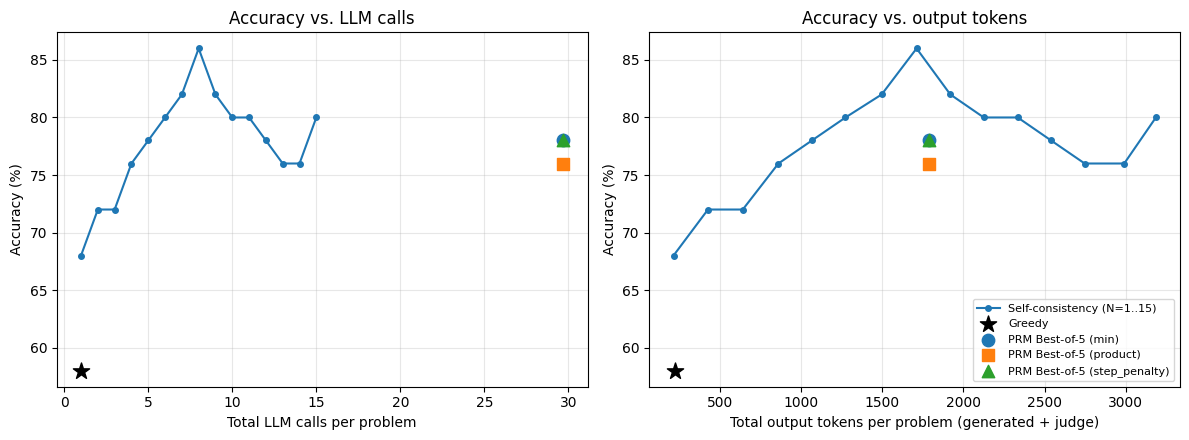

In [11]:
# 95% bootstrap CIs (1,000 resamples, seed 5326) and paired win/loss
methods = ["greedy", "sc5", "sc15", "prm_min", "prm_product", "prm_step_penalty"]
C = {m: np.array([r["correct"][m] for r in records], dtype=float) for m in methods}
boot = np.random.default_rng(5326).integers(0, N, size=(1000, N))

for m in methods:
    lo, hi = np.percentile(C[m][boot].mean(axis=1) * 100, [2.5, 97.5])
    print(f"{m:<18} {C[m].mean() * 100:5.1f}%  95% CI [{lo:5.1f}, {hi:5.1f}]")

print()
for s in STRATEGIES:
    for base in ["sc5", "sc15"]:
        a, b = C[f"prm_{s}"], C[base]
        win, loss = int(((a == 1) & (b == 0)).sum()), int(((a == 0) & (b == 1)).sum())
        lo, hi = np.percentile((a[boot] - b[boot]).mean(axis=1) * 100, [2.5, 97.5])
        print(f"prm_{s} vs {base}: wins {win}, losses {loss}, ties {N - win - loss}, "
              f"diff CI [{lo:.1f}, {hi:.1f}]")

# Scaling plots
prm_calls = 5 + judge_calls / N
prm_tok = avg_gen(5) + avg_judge_tok
sc_acc = [c["Accuracy (%)"] for c in curve]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, xs, px, gx, xlabel in [
        (axes[0], [c["N"] for c in curve], prm_calls, 1, "Total LLM calls per problem"),
        (axes[1], [c["Avg Gen Tokens / Problem"] for c in curve], prm_tok, greedy_tok,
         "Total output tokens per problem (generated + judge)")]:
    ax.plot(xs, sc_acc, "-o", ms=4, label="Self-consistency (N=1..15)")
    ax.scatter([gx], [acc("greedy")], marker="*", s=150, color="k", zorder=3, label="Greedy")
    for s, mk in zip(STRATEGIES, ["o", "s", "^"]):
        ax.scatter([px], [acc(f"prm_{s}")], marker=mk, s=80, zorder=3, label=f"PRM Best-of-5 ({s})")
    ax.set_xlabel(xlabel); ax.set_ylabel("Accuracy (%)"); ax.grid(alpha=0.3)
axes[0].set_title("Accuracy vs. LLM calls")
axes[1].set_title("Accuracy vs. output tokens")
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/scaling_plots.png", dpi=200)
plt.show()

In [12]:
# Failure cases: judge false positive, judge false negative, mode collapse
def show_path(r, ci):
    c = r["candidates"][ci]
    print(f"[{r['id']}] candidate {ci} | answer={c['answer']} | truth={r['ground_truth']}")
    print("Q:", r["question"])
    for k, step in enumerate(c["steps"]):
        v = "VALID  " if c["step_scores"][k] > 0 else "INVALID"
        print(f"  Step {k + 1} [{v}] {step}\n      rationale: {c['rationales'][k]}")
    print("-" * 90)

fp, fn, collapse = [], [], []
for r in records:
    gt, cands = r["ground_truth"], r["candidates"][:5]
    for ci, c in enumerate(cands):
        if c["step_scores"] and min(c["step_scores"]) > 0 and c["answer"] != gt:
            fp.append((r, ci))
        if c["step_scores"] and min(c["step_scores"]) < 0 and c["answer"] == gt:
            fn.append((r, ci))
    answers = {c["answer"] for c in cands}
    if len(answers) == 1 and None not in answers and gt not in answers:
        collapse.append(r)

print(f"False positives: {len(fp)} | False negatives: {len(fn)} | Mode collapse: {len(collapse)}\n")
print("=== Judge false positive ===");  [show_path(r, ci) for r, ci in fp[:2]]
print("=== Judge false negative ===");  [show_path(r, ci) for r, ci in fn[:2]]
print("=== Mode collapse ===");          [show_path(r, 0) for r in collapse[:2]]

# Judge audit sample: 20 steps judged INVALID + 20 judged VALID
all_steps = [{"id": r["id"], "cand": ci, "step": k + 1, "question": r["question"],
              "prev": c["steps"][:k], "text": s,
              "judge": "VALID" if c["step_scores"][k] > 0 else "INVALID",
              "rationale": c["rationales"][k]}
             for r in records for ci, c in enumerate(r["candidates"][:5])
             for k, s in enumerate(c["steps"])]
rnd = random.Random(5326)
inv = [s for s in all_steps if s["judge"] == "INVALID"]
val = [s for s in all_steps if s["judge"] == "VALID"]
n_inv = min(20, len(inv))
audit = rnd.sample(inv, n_inv) + rnd.sample(val, min(40 - n_inv, len(val)))

print("\n\n=== Judge audit sample ===")
for i, s in enumerate(audit):
    print(f"#{i} [{s['id']} cand {s['cand']} step {s['step']}] judge={s['judge']}")
    print("   Q:", s["question"])
    for j, prev in enumerate(s["prev"], 1):
        print(f"   Step {j}: {prev}")
    print(f"   >> CURRENT: {s['text']}\n   rationale: {s['rationale']}\n")

False positives: 21 | False negatives: 38 | Mode collapse: 0

=== Judge false positive ===
[gsm8k_test_01] candidate 1 | answer=48 | truth=18
Q: Janet's ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?
  Step 1 [VALID  ] Calculate the total number of eggs laid per day.
Janet's ducks lay 16 eggs per day.
      rationale: The calculation is correct based on the information provided.
  Step 2 [VALID  ] Calculate the number of eggs eaten for breakfast.
Janet eats 3 eggs for breakfast every morning.
      rationale: The calculation is correct and follows from the problem statement.
  Step 3 [VALID  ] Calculate the number of eggs used to bake muffins.
Janet uses 4 eggs to bake muffins.
      rationale: The arithmetic is correct and it follows logically from the problem st

In [13]:
# Hand labels for the audit sample above (audit number -> "VALID" / "INVALID")
# Each step was checked under local validity: earlier steps are assumed correct.
human_labels = {
    # ---- judge said INVALID ----
    0: "VALID",     # -28 / 2 = -14 is correct; the error was in an earlier step
    1: "INVALID",   # "1250 - 200 = 1050 remaining calories" is a meaningless quantity here
    2: "VALID",     # restates the problem
    3: "VALID",     # H = 2 x 33 matches the problem
    4: "INVALID",   # 100 - 40 = 60 labelled "time for first 60%" is wrong reasoning
    5: "VALID",     # 99 / 2 = 49.5 is correct
    6: "VALID",     # 120 - (15 + 25) = 80; arithmetic right, 15 and 25 from the problem
    7: "VALID",     # 80 x 60 = 4800 follows from step 3
    8: "INVALID",   # 16 glasses = 1 x $5 + 15 x $3, but only 14 x $3 is used
    9: "VALID",     # 4 + 1 = 5 is correct
    10: "VALID",    # summing the water before the spill is a valid step
    11: "VALID",    # 60 - 20 = 40 is correct
    12: "INVALID",  # 20 blue ties is unjustified (200 / 40 = 5)
    13: "INVALID",  # "12 hours / 24 = 0.5 mph" is nonsense
    14: "INVALID",  # hip-hop is 12 students, not 0
    15: "INVALID",  # total time is 3 + 1.5 + 1.5 = 6 hours, not 9 + 3
    16: "INVALID",  # "number of lego sets = money" is nonsense
    17: "VALID",    # 96 - 125 = -29 is correct arithmetic
    18: "INVALID",  # "15 days in a month" is invented and irrelevant
    19: "VALID",    # 4 miles in 1 hour = 4 mph
    # ---- judge said VALID ----
    20: "VALID",    # 2 / 2 = 1
    21: "VALID",    # 4 x 1.50 = 6
    22: "VALID",    # 13 - 4 = 9
    23: "VALID",    # 11 x 9 = 99
    24: "VALID",    # 5 x 8 = 40
    25: "VALID",    # 84 / 12 = 7
    26: "VALID",    # 33 + 66 = 99
    27: "INVALID",  # 80 GB at 2 GB/min takes 40 min, not 20
    28: "VALID",    # 5 x 3 = 15
    29: "VALID",    # 180 x 0.7 = 126
    30: "VALID",    # 40 / 2 + 5 = 25
    31: "VALID",    # 3 x 60 = 180
    32: "VALID",    # adds both weekly earnings
    33: "VALID",    # 0 DVDs from the last 3 customers
    34: "INVALID",  # born 6 years earlier means 31 + 6 = 37, not 25
    35: "VALID",    # refers to the wrong step number, but no wrong math
    36: "VALID",    # 40 - 20 = 20 follows from step 1
    37: "VALID",    # 0.5 hours per dog per day
    38: "VALID",    # 5 x 0.60 = 3
    39: "VALID",    # 60 x 3 = 180
}

TP = FP = TN = FN = 0   # positive class = INVALID
for i, label in human_labels.items():
    j_inv, h_inv = audit[i]["judge"] == "INVALID", label.upper() == "INVALID"
    TP += j_inv and h_inv
    FP += j_inv and not h_inv
    FN += (not j_inv) and h_inv
    TN += (not j_inv) and (not h_inv)

print(f"Labeled: {len(human_labels)} | TP={TP} FP={FP} TN={TN} FN={FN}")
if TP + FP: print(f"Precision (INVALID): {TP / (TP + FP):.2f}")
if TP + FN: print(f"Recall (INVALID):    {TP / (TP + FN):.2f}")

Labeled: 40 | TP=9 FP=11 TN=18 FN=2
Precision (INVALID): 0.45
Recall (INVALID):    0.82


In [14]:
# Compute efficiency (budget = 10x greedy generated tokens) and reproducibility
import transformers, bitsandbytes, platform

budget = 10 * greedy_tok
print(f"Greedy tokens/problem: {greedy_tok:.1f} -> 10x budget: {budget:.1f}")
print(f"PRM Best-of-5 spend: {prm_tok:.1f} (generated {avg_gen(5):.1f} + judge {avg_judge_tok:.1f})")
fits = [c for c in curve if c["Avg Gen Tokens / Problem"] <= budget]
if fits:
    print(f"Largest SC within budget: N={fits[-1]['N']} -> {fits[-1]['Accuracy (%)']}%")
print(f"PRM (min) accuracy: {acc('prm_min')}%")

judge_prompt = np.mean([len(judge_tokenizer(A.build_prm_judge_prompt(s["question"], s["prev"], s["text"]))["input_ids"])
                        for s in all_steps[:200]])
gen_prompt = np.mean([len(gen_tokenizer(A.format_step_prompt(r["question"]))["input_ids"]) for r in records])
print(f"Generator call: prompt {gen_prompt:.0f} tok -> output {avg_gen(5) / 5:.0f} tok")
print(f"Judge call:     prompt {judge_prompt:.0f} tok -> output {avg_judge_tok / max(1, judge_calls / N):.0f} tok")

print(f"\nPython {platform.python_version()} | torch {torch.__version__} | "
      f"transformers {transformers.__version__} | bitsandbytes {bitsandbytes.__version__}")
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")
total = sum(sum(r["times"].values()) for r in records)
print(f"Total measured runtime: {total / 60:.1f} min | seed: 5326 + problem_index")

Greedy tokens/problem: 222.9 -> 10x budget: 2229.0
PRM Best-of-5 spend: 1788.9 (generated 1066.4 + judge 722.5)
Largest SC within budget: N=10 -> 80.0%
PRM (min) accuracy: 78.0%
Generator call: prompt 197 tok -> output 213 tok
Judge call:     prompt 337 tok -> output 29 tok

Python 3.13.16 | torch 2.11.0+cu130 | transformers 5.20.2 | bitsandbytes 0.50.2
GPU 0: Tesla T4
GPU 1: Tesla T4
Total measured runtime: 74.4 min | seed: 5326 + problem_index


In [15]:
!zip -qr /kaggle/working/pa3_outputs.zip src submission_adapter.py outputs
!ls -la outputs

total 1672
drwxr-xr-x 2 root root    4096 Nov 14 19:15 .
drwxr-xr-x 8 root root    4096 Nov 14 17:58 ..
-rw-r--r-- 1 root root     545 Nov 14 19:15 aggregation_ablation.json
-rw-r--r-- 1 root root      18 Nov 14 17:57 .gitkeep
-rw-r--r-- 1 root root   79790 Nov 14 18:08 greedy_cache.jsonl
-rw-r--r-- 1 root root 1474433 Nov 14 19:15 per_problem.jsonl
-rw-r--r-- 1 root root    1606 Nov 14 19:15 results_summary.json
-rw-r--r-- 1 root root  122710 Nov 14 19:15 scaling_plots.png
-rw-r--r-- 1 root root    1306 Nov 14 19:15 sc_scaling_curve.json
